# `ammico` workshop November 2026: comparing models with OpenRouter

*Delia Dumitrescu, Inga Ulusoy, Dmitrii Kapitan*

With `ammico`, you can analyze text on images and image content at the same time, see https://ssciwr.github.io/AMMICO/. In this notebook, we run the same analysis with several vision-language models hosted on [OpenRouter](https://openrouter.ai) and compare the results. First we start by importing the packages.

In [1]:
import openrouter_utils as OR

import ammico

This imports all the functionality from `ammico`. To analyze images, you can manually upload images to the Jupyter server; in this workshop, we will use pre-prepared datasets in `/home/jovyan/data_mounts/webdav`. The helper functions for running several models are in `openrouter_utils.py`, next to this notebook.

# Step 1: Read your data into AMMICO

`ammico` reads in files from a directory. You can iterate through directories in a recursive manner and filter by extensions. Note that the order of the files may vary on different OS. Reading in these files creates a dictionary `image_dict`, with one entry per image file, containing the file path and filename. This dictionary is the main data structure that ammico operates on and is extended successively with each detector run as explained below.

For reading in the files, the ammico function `find_files` is used, with optional keywords:

| input key | input type | possible input values |
| --------- | ---------- | --------------------- |
`path` | `str` | the directory containing the image files (defaults to the location set by environment variable `AMMICO_DATA_HOME`) |
| `pattern` | `str\|list` | the file extensions to consider (defaults to "png", "jpg", "jpeg", "gif", "webp", "avif", "tiff") |
| `recursive` | `bool` | include subdirectories recursively (defaults to `True`) |
| `limit` | `int` | maximum number of files to read (defaults to `20`, for all images set to `None` or `-1`) |
| `random_seed` | `int` | the random seed for shuffling the images; applies when only a few images are read and the selection should be preserved (defaults to `None`) |

Since every model is billed per request on OpenRouter, you may want to start with a small number of images by setting `limit`. All models are run on exactly the same images.

In [2]:
# Define your data path
data_path = (
    "/home/jovyan/data_mounts/webdav/dataset_symbols/"  # the selected directory
)

# Find files and create the image dictionary
image_dict = ammico.find_files(
    path=data_path,
    limit=-1,  # Limit the number of files to process (optional)
)

# 2. Connect to the models

We will ask the same questions about the images to several vision-language models and compare their answers.

[OpenRouter](https://openrouter.ai) gives access to many hosted models (OpenAI, Google, Anthropic, Qwen, Meta, Mistral, ...) through a single **OpenAI-compatible API** and a single API key. You need an account and an API key, which you can create at [openrouter.ai/keys](https://openrouter.ai/keys). The key is read from the environment variable `OPENROUTER_API_KEY`; if it is not set, you are asked to enter it below. Do not write your API key directly into the notebook, in particular if you share the notebook with others!

**Privacy note:** with OpenRouter your images are sent to a third party (OpenRouter and the provider of the selected model). Do not use this setup for data that must not leave your institution.

Any model on OpenRouter that accepts images as input can be used, see the [OpenRouter model list](https://openrouter.ai/models?input_modalities=image), where you also see the price per token. The model id is the name shown on the model page, prefixed with the provider, for example `openai/gpt-4o-mini`. Add or remove model ids in the list below.

In [3]:
# Connect to OpenRouter (asks for the API key if OPENROUTER_API_KEY is not set)
OR.connect()

models = [
    "google/gemini-2.5-flash",
    "qwen/qwen2.5-vl-72b-instruct",
    "meta-llama/llama-4-maverick",
]

Enter your OpenRouter API key:  ········


Connected to OpenRouter (key starts with 'sk-or-v1').


Then, we create an instance of the Python class that handles the visual question answering task. It holds one `ammico.ImageSummaryDetector` per model, each working on its own copy of `image_dict`, so that the results of the different models do not overwrite each other.

Many models on OpenRouter are served from a pool shared between all users. When it is busy, the request is rejected with a **rate limit error** (`Error code: 429`); such requests are retried with increasing waiting times. To avoid the rate limit, the number of requests sent at the same time is limited by `max_parallel_images` and `max_parallel_requests` (one request per question); lower these numbers if you still see many rate limit errors. Reasoning models "think" before they answer, which can leave the answer empty, so reasoning is switched off (`disable_reasoning=True`).

In [4]:
image_summary_vqa = OR.MultiModelDetector(
    models,
    image_dict,
    max_parallel_images=4,  # images processed at the same time
    max_parallel_requests=2,  # requests (questions) per image at the same time
    disable_reasoning=True,
)

# 3. Run the content analysis: Visual question answering

Now we ask questions about the images. For this, provide a list of questions and pass it to the Python class that you have instantiated above. All models answer the same questions:

In [5]:
list_of_questions = [
    "Does the picture depict a national or EU symbol?",
    "Does the picture depict a national or EU symbol, such as a national emblem, a national flag, or the EU flag? Do not guess.",
    "Does the picture depict a national or EU symbol, such as a national emblem, a national flag, or the EU flag? Take into account both instances when the symbol, such as the flag or the emblem, appears in full and when only parts of it are visible. Do not guess.", 
    "Does the picture depict any national or EU symbol, either in part or in full? Consider the situation that the symbol might be blended in the image, but do not guess.",
]

In [6]:
answers = image_summary_vqa.analyse_images_from_dict(
    analysis_type="questions",
    list_of_questions=list_of_questions,
    is_concise_summary=True,
    is_concise_answer=True,
)

google/gemini-2.5-flash: running on 141 images ...
google/gemini-2.5-flash: done in 64.9 s
qwen/qwen2.5-vl-72b-instruct: running on 141 images ...
qwen/qwen2.5-vl-72b-instruct: done in 86.6 s
meta-llama/llama-4-maverick: running on 141 images ...
meta-llama/llama-4-maverick: done in 89.2 s


Again for your convenience we display the images and the answers of all models to the questions together below:

In [ ]:
OR.show_answers(answers, list_of_questions)

# 4. Export the results

To export the results for further processing, convert the image dictionaries of all models into one pandas dataframe. Each row corresponds to one image analyzed by one model; the column `model` tells you which model produced the result.

In [7]:
image_df = OR.get_dataframe(answers)

Inspect the dataframe:

In [8]:
image_df.head(5)

,model,filename,vqa
0,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_symbol...,"[Yes, the picture depicts both national (Spani..."
1,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_symbol...,"[No, the picture does not depict a national or..."
2,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_symbol...,"[Yes, the picture depicts a national symbol. T..."
3,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_symbol...,"[No, the picture does not depict a national or..."
4,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_symbol...,"[No, the picture does not depict a national or..."


Export the dataframe to a csv file, and additionally the results of each model to its own csv file (`<provider>__<model>.csv`):

In [9]:
image_df.to_csv("./symbols_data_out.csv")
OR.save_per_model(image_df, "./symbols_results")

google/gemini-2.5-flash: saved to symbols_results/google__gemini-2.5-flash.csv
qwen/qwen2.5-vl-72b-instruct: saved to symbols_results/qwen__qwen2.5-vl-72b-instruct.csv
meta-llama/llama-4-maverick: saved to symbols_results/meta-llama__llama-4-maverick.csv


# 5. Analyse the results
You can compare the results to the manual labels and observe how accurate the different VLMs capture the content.

# Question accuracy for several models

Which of several questions (prompts) gets the most images right for each model, and do the models agree on which question works best?

**How to use:** run the VQA with ammico on one of the course datasets and save the result as a csv file. Fill in the two paths in the next cell and run all cells. Tables and plots are saved in `comparison_results/` next to the (first) result file.

In [10]:
# ============ SETTINGS: the only cell you need to change ============
RESULTS_FILES = [  # csv file(s) with the model answers, one file per model
    "/home/jovyan/symbols_results/google__gemini-2.5-flash.csv",  # (or one file with several models); glob patterns work,
    "/home/jovyan/symbols_results/meta-llama__llama-4-maverick.csv",  # e.g. "../my_results/emotions_*.csv"
    "/home/jovyan/symbols_results/qwen__qwen2.5-vl-72b-instruct.csv",  # e.g. "../my_results/emotions_*.csv"
]
IMAGE_DIR = data_path  # folder with the images, here the same as above

**Datasets** – the dataset (emotions, politicians or symbols) is detected from the image names in the result file, so only the paths change. The paths are relative to this notebook.

The images can be in one flat folder; they are only needed for the image examples. Questions, ground truth and expected answers are defined in `DATASETS` in `vqa_eval_utils.py`; the ground-truth and question files are read from `ground_truth/` next to the image folder (or from the `*_output/` folders of the course repository). The answers must be to the questions in these files, in the same order.

## 5.1 Data and questions

In [11]:
import vqa_eval_utils as U

run = U.load(RESULTS_FILES, IMAGE_DIR, "question_accuracy_models")
U.show_questions(run)

dataset: symbols  |  models: gemini-2.5-flash, llama-4-maverick, qwen2.5-vl-72b-instruct
images: 141 in the results, 141 with ground truth, 141 found in /home/jovyan/data_mounts/webdav/dataset_symbols/
images answered completely by all models (used for the comparison): 141
output folder: /home/jovyan/symbols_results/comparison_results/question_accuracy_models


,type,style,question,expected answer (label -> answer)
qid,,,,
Q1,symbol,open,Does the picture depict a national or EU symbol?,"1 -> yes, 0 -> no"
Q2,symbol,examples,"Does the picture depict a national or EU symbol, such as a national emblem, a national flag, or the EU flag? Do not guess.","1 -> yes, 0 -> no"
Q3,symbol,examples+partial,"Does the picture depict a national or EU symbol, such as a national emblem, a national flag, or the EU flag? Take into account both instances when the symbol, such as the flag or the emblem, appea...","1 -> yes, 0 -> no"
Q4,symbol,partial+blended,"Does the picture depict any national or EU symbol, either in part or in full? Consider the situation that the symbol might be blended in the image, but do not guess.","1 -> yes, 0 -> no"


## 5.2 From free text to answers
Each answer is mapped to a category (yes / no / dk, …) by the rules of its question type. `exact`, `first` and `package_code` are safe; the keyword rules (`kw_*`) are heuristics, so read the sample of raw answers below against their `normalised` value. Only images answered by all models are used, so all models are compared on the same images.

In [12]:
U.show_normalisation(run)

answer_is  exact  first  kw_affirm  kw_dk  kw_negated  unparsed
qid model                                                                                   
Q1  gemini-2.5-flash                 0     10    106         21      0           1         3
    llama-4-maverick                 4     10     29         65      0          30         3
    qwen2.5-vl-72b-instruct          0     73      0         36      0          14        18
Q2  gemini-2.5-flash                 0     32    107          2      0           0         0
    llama-4-maverick                10     60     30         22      3          16         0
    qwen2.5-vl-72b-instruct          0     94      0         39      0           7         1
Q3  gemini-2.5-flash                 0     10    130          1      0           0         0
    llama-4-maverick                 4     90     12         28      0           7         0
    qwen2.5-vl-72b-instruct          0     91      0         34      0          15         1
Q4  gemini-2.5-flash                 0      1    140          0      0           0         0
    llama-4-maverick                16     18     34         22      1          49         1
    qwen2.5-vl-72b-instruct          0    116     25          0      0           0         0

375 distinct keyword-mapped or unparsed answers (all in /home/jovyan/symbols_results/comparison_results/question_accuracy_models/mapping_review.csv); sample:


,model,qid,rule,normalised,raw
15,gemini-2.5-flash,Q1,unparsed,unparsed,National.
16,gemini-2.5-flash,Q1,unparsed,unparsed,Both.
99,llama-4-maverick,Q1,unparsed,unparsed,The image contains a symbol associated with the European Union.
100,llama-4-maverick,Q1,unparsed,unparsed,"The image depicts a map of Europe, which is a symbol associated with the EU."
101,llama-4-maverick,Q1,unparsed,unparsed,"The picture depicts a warning symbol, which is not specific to a particular nation or the EU. However, the symbol is commonly used in many countries, including those in the EU, to indicate caution..."
233,llama-4-maverick,Q4,unparsed,unparsed,"The image contains a partial depiction of a map of Europe, which is a geographical representation and not a symbol per se, but it is related to the EU."
284,qwen2.5-vl-72b-instruct,Q1,unparsed,unparsed,EU
285,qwen2.5-vl-72b-instruct,Q1,unparsed,unparsed,national
325,qwen2.5-vl-72b-instruct,Q2,unparsed,unparsed,EU
374,qwen2.5-vl-72b-instruct,Q3,unparsed,unparsed,EU


> **Result:** 141 images have results and a ground-truth label (label: number of images – 0: 84, 1: 57). 474 of 1692 answers needed keyword rules and 27 remain unparsed.

## 5.3 Accuracy per question
**Accuracy** = share of images whose (normalised) answer matches the expected answer from the ground truth. DK, unclear and unparsed answers count as **wrong**; images without an expected answer (e.g. label `unclear`) are not scored.
The **majority baseline** is the accuracy of always giving the most frequent expected answer – a question is only useful if it beats it clearly. Error bars are 95% Wilson confidence intervals.

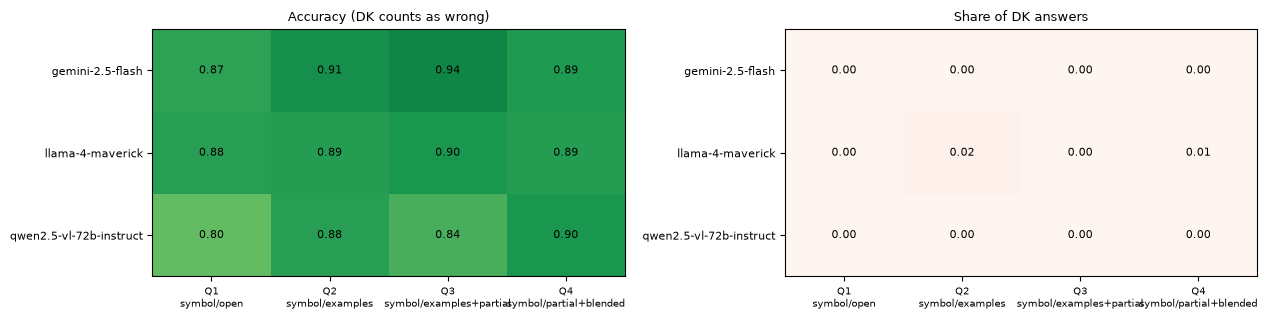

qid,Q1,Q2,Q3,Q4
majority_baseline,0.596,0.596,0.596,0.596


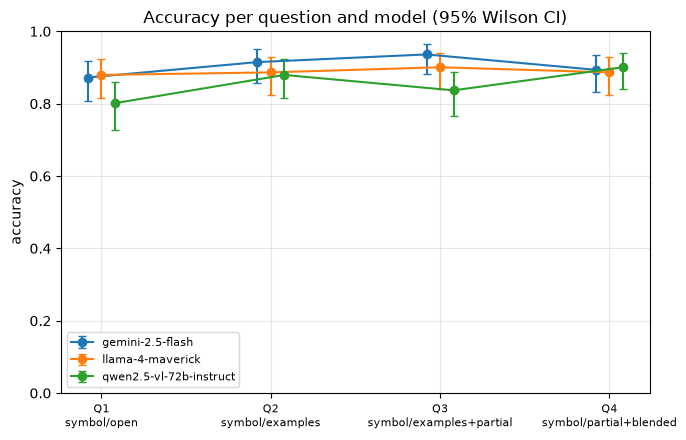

> **Result:** Accuracy range per model: gemini-2.5-flash 0.87–0.94 (best Q3), llama-4-maverick 0.88–0.90 (best Q3) and qwen2.5-vl-72b-instruct 0.80–0.90 (best Q4). The best combination is gemini-2.5-flash with Q3 (0.94).  The models agree most on Q4 (spread 0.01) and differ most on Q3 (spread 0.10 between the best and the worst model).

In [13]:
acc = U.show_accuracy(run)

## 5.4 Accuracy per image group
The same accuracy for each image group and model: a low value shows which kind of image makes a question fail.

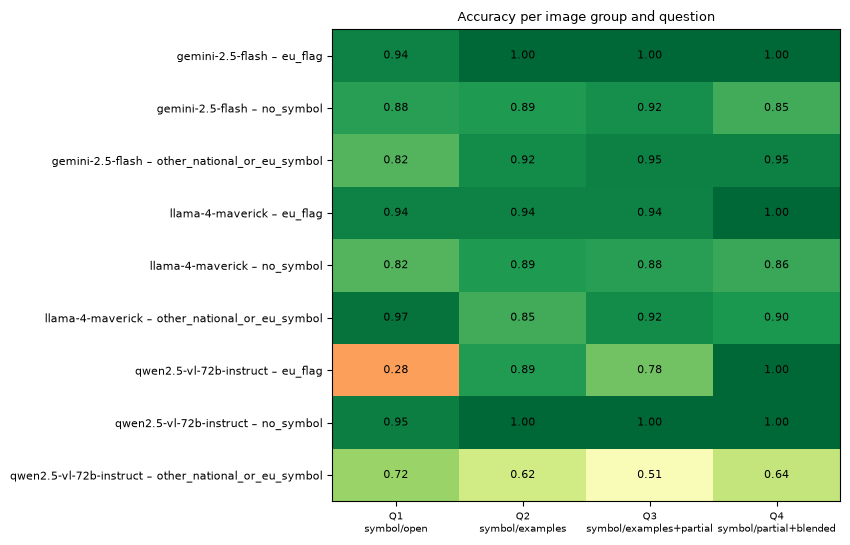

> **Result:** Weakest group and question per model – gemini-2.5-flash: other_national_or_eu_symbol with Q1 (0.82), llama-4-maverick: no_symbol with Q1 (0.82) and qwen2.5-vl-72b-instruct: eu_flag with Q1 (0.28).

In [14]:
U.show_groups(run, acc)

## 5.5 Which differences between questions are significant?
Each pair of questions is compared on the same images with an exact McNemar test (Holm-corrected). Blue = the row question is more accurate, red = less accurate, * = significant.

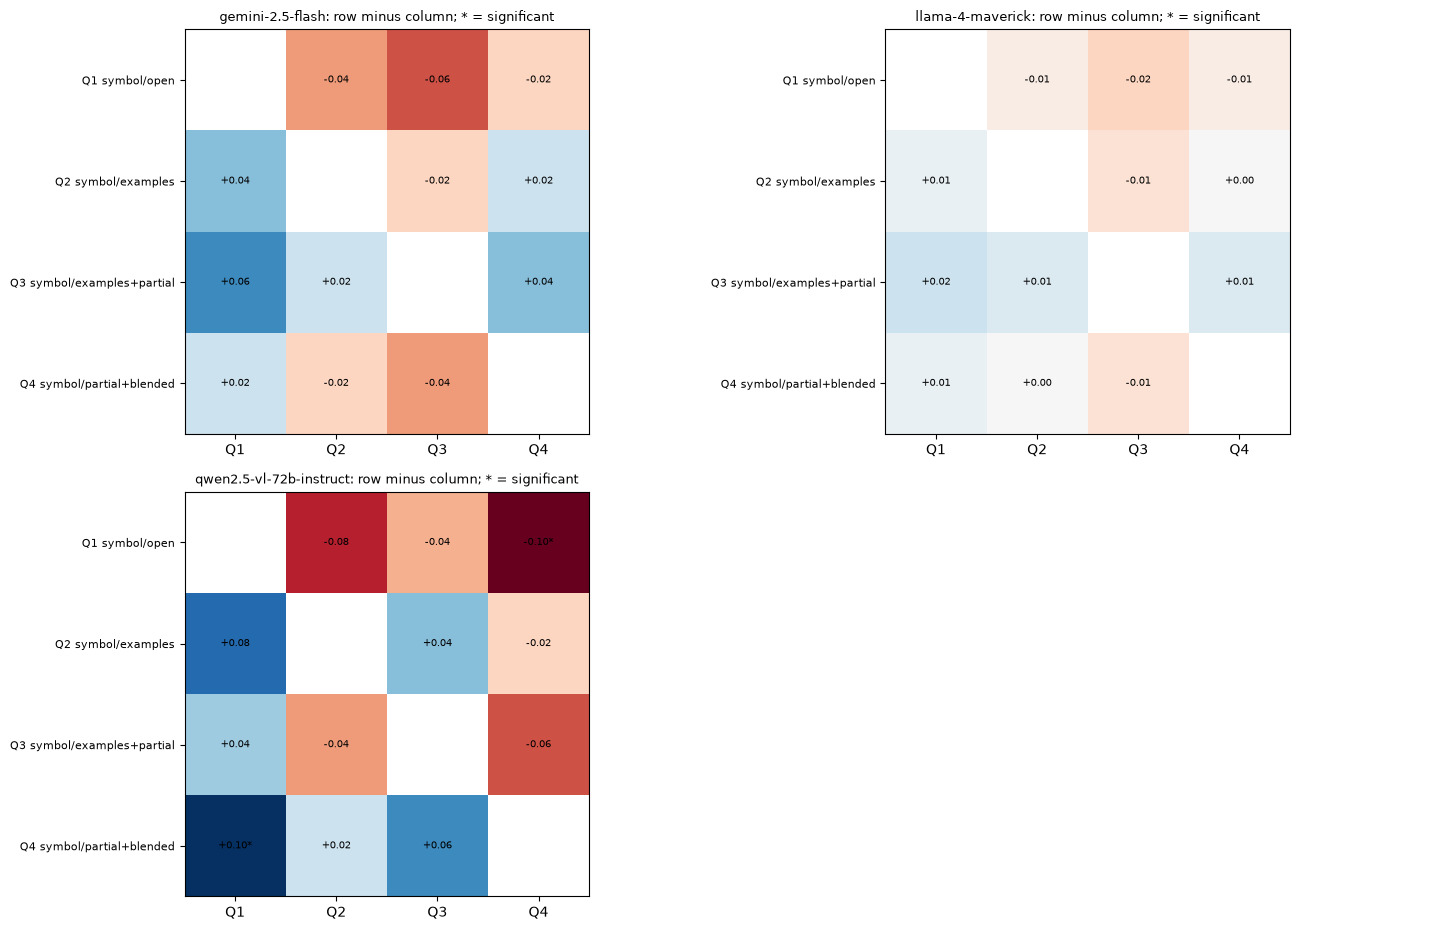

> **Result:** Significant question differences (of 6 pairs): gemini-2.5-flash 0, llama-4-maverick 0 and qwen2.5-vl-72b-instruct 1. 

In [15]:
tests = U.show_pairs(run)

## 5.6 Summary: which question to use?
The most accurate question per model and the questions that are not significantly worse. A question that is never significantly worse is a safe choice across models.

In [16]:
U.show_best(run, acc, tests)

,model,best_question,best_accuracy,not_significantly_worse,worst_question,worst_accuracy,mean_accuracy
0,gemini-2.5-flash,Q3,0.936,"Q1, Q2, Q3, Q4",Q1,0.872,0.904
1,llama-4-maverick,Q3,0.901,"Q1, Q2, Q3, Q4",Q1,0.879,0.888
2,qwen2.5-vl-72b-instruct,Q4,0.901,"Q2, Q3, Q4",Q1,0.801,0.855


> **Result:** Best question per model – gemini-2.5-flash: Q3 (0.94), llama-4-maverick: Q3 (0.90) and qwen2.5-vl-72b-instruct: Q4 (0.90). Q2, Q3 and Q4 are the best or not significantly worse than the best for every model, i.e. a safe choice across models.

## 5.7 Difficult images
How many answers go wrong per image, and the hardest images of each group. Errors on every question point to a hard image or a questionable label; errors on some questions point to the wording.

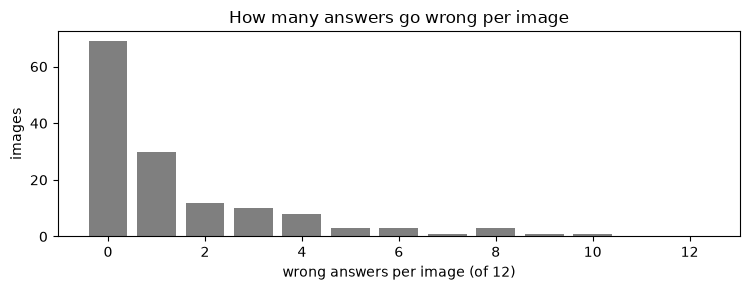

,,images,mean_share_wrong,hard_images (≥50% wrong)
group,subfolder,,,
other_national_or_eu_symbol,natl_eu_flags,39,0.19,5
eu_flag,eu flags,18,0.11,0
no_symbol,no_natl_eu_flags,84,0.09,4


> **Result:** 69 of 141 images are answered correctly in all 12 answers, and 9 are wrong in half or more (5 other_national_or_eu_symbol, 4 no_symbol). The hardest group is other_national_or_eu_symbol (19% wrong answers on average), the easiest no_symbol (9%).

**Hardest images per group** – left: the image; right: expected answer (first row) and normalised answers, green = correct, red = wrong. Below: the raw wrong answers.

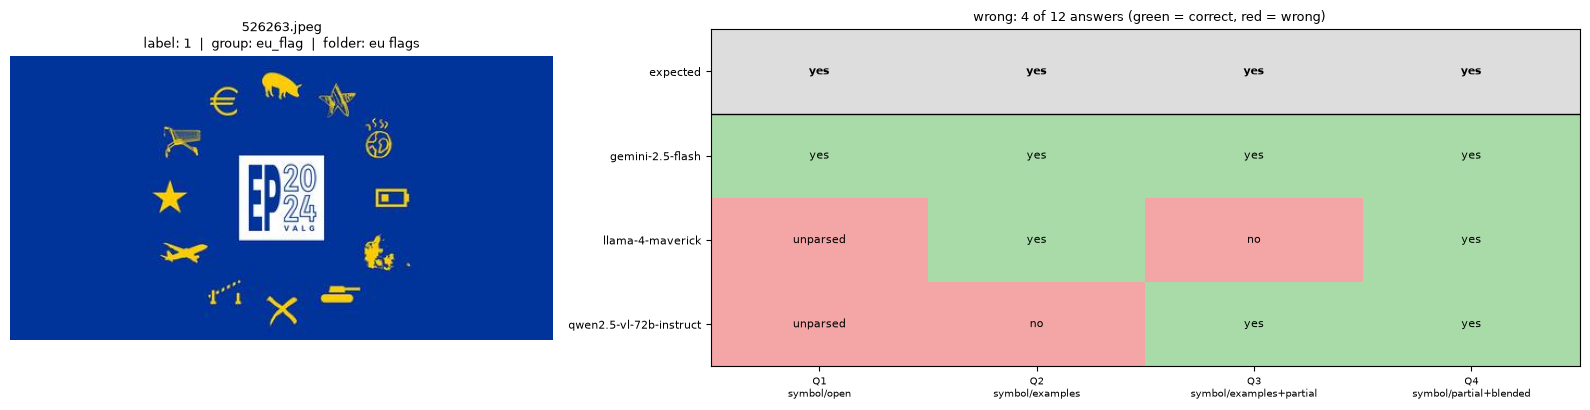

,model,qid,truth,pred,raw
0,llama-4-maverick,Q1,yes,unparsed,The image contains a symbol associated with the European Union.
1,qwen2.5-vl-72b-instruct,Q1,yes,unparsed,EU
2,qwen2.5-vl-72b-instruct,Q2,yes,no,"The picture does not depict a national or EU symbol such as a national emblem, a national flag, or the EU flag. It is related to the European Parliament electio"
3,llama-4-maverick,Q3,yes,no,"The image does not depict a national or EU symbol. However, it does contain the Euro symbol."


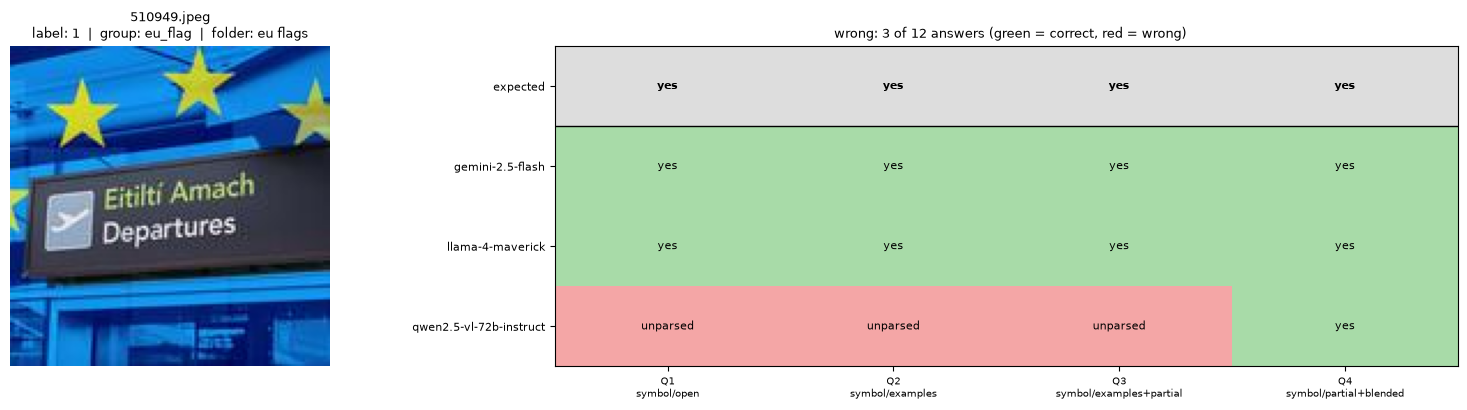

,model,qid,truth,pred,raw
0,qwen2.5-vl-72b-instruct,Q1,yes,unparsed,EU
1,qwen2.5-vl-72b-instruct,Q2,yes,unparsed,EU
2,qwen2.5-vl-72b-instruct,Q3,yes,unparsed,EU


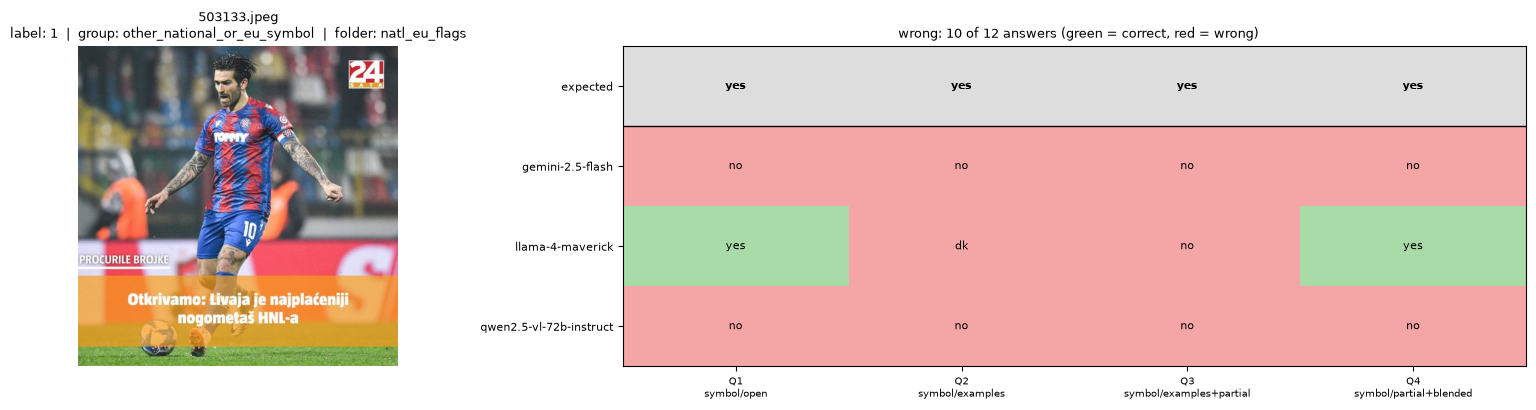

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,yes,no,"No, the picture does not depict a national or EU symbol."
1,qwen2.5-vl-72b-instruct,Q1,yes,no,No
2,gemini-2.5-flash,Q2,yes,no,No.
3,llama-4-maverick,Q2,yes,dk,The image does not clearly depict a national or EU symbol. The jersey worn by the individual in the image features a logo that could be interpreted as a nationa
4,qwen2.5-vl-72b-instruct,Q2,yes,no,No
5,gemini-2.5-flash,Q3,yes,no,"No, the picture does not depict a national or EU symbol."
6,llama-4-maverick,Q3,yes,no,The image does not depict a national or EU symbol.
7,qwen2.5-vl-72b-instruct,Q3,yes,no,No
8,gemini-2.5-flash,Q4,yes,no,"No, the picture does not depict any national or EU symbol, either in part or in full."
9,qwen2.5-vl-72b-instruct,Q4,yes,no,No


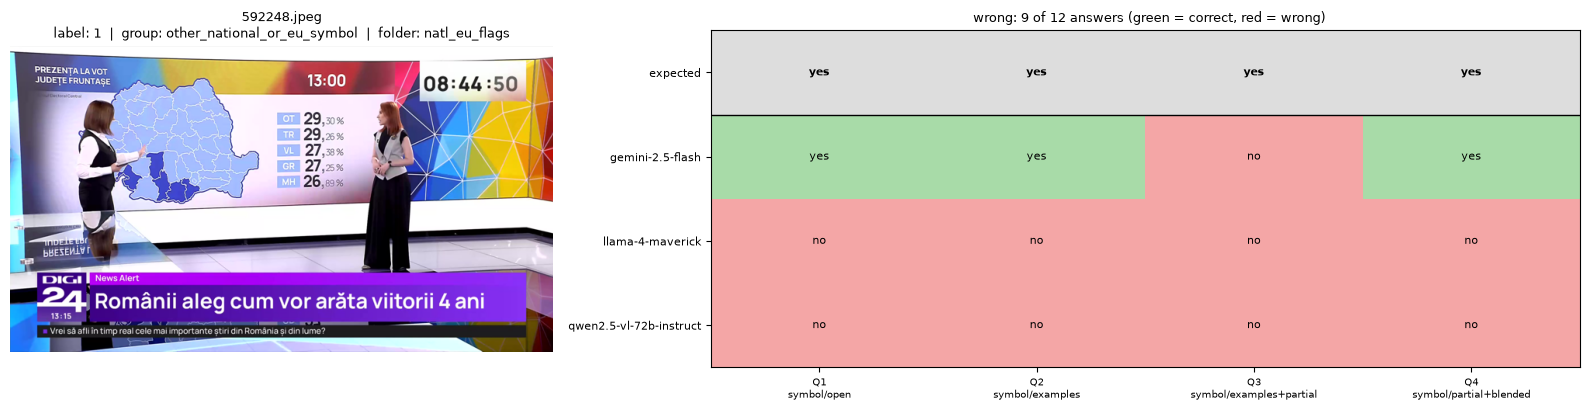

,model,qid,truth,pred,raw
0,llama-4-maverick,Q1,yes,no,The image does not depict a national or EU symbol.
1,qwen2.5-vl-72b-instruct,Q1,yes,no,"The picture does not depict a national or EU symbol. It shows a map of Romania with various regions highlighted, along with statistical data and two women discu"
2,llama-4-maverick,Q2,yes,no,The image does not depict a national or EU symbol.
3,qwen2.5-vl-72b-instruct,Q2,yes,no,No
4,gemini-2.5-flash,Q3,yes,no,"No, the picture does not depict a national or EU symbol."
5,llama-4-maverick,Q3,yes,no,No national or EU symbol is depicted in the image.
6,qwen2.5-vl-72b-instruct,Q3,yes,no,No
7,llama-4-maverick,Q4,yes,no,"The image does not depict any national or EU symbol, either in part or in full. The colors of the Romanian flag (blue, yellow, and red) are visible on the right"
8,qwen2.5-vl-72b-instruct,Q4,yes,no,No


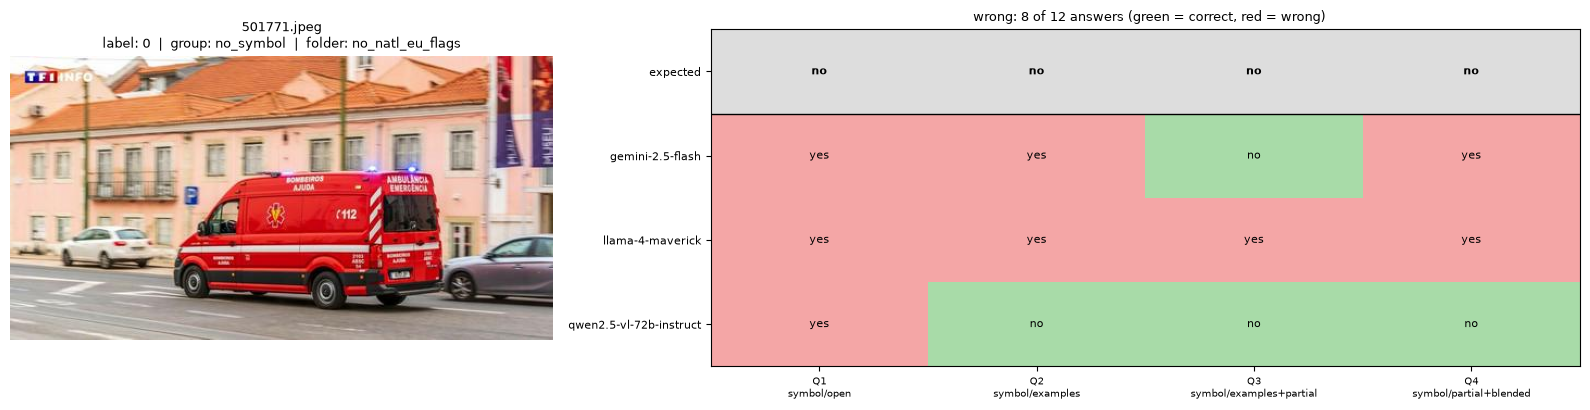

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,no,yes,"Yes, the picture depicts an EU symbol. The number ""112"" is visible on the ambulance, which is the standard emergency telephone number across the European Union."
1,llama-4-maverick,Q1,no,yes,"The image shows a red ambulance with a yellow emblem on its side, which is likely a national symbol. The number ""112"" is also visible on the ambulance, which is"
2,qwen2.5-vl-72b-instruct,Q1,no,yes,"The picture depicts a national symbol. The ambulance in the image has a red cross emblem, which is a widely recognized symbol for medical services and emergency"
3,gemini-2.5-flash,Q2,no,yes,"Yes, the picture depicts an EU symbol. The number ""112"" is visible on the side of the ambulance, which is the standard emergency telephone number across the Eur"
4,llama-4-maverick,Q2,no,yes,Yes.
5,llama-4-maverick,Q3,no,yes,Yes.
6,gemini-2.5-flash,Q4,no,yes,"Yes, the picture depicts an EU symbol. The number ""112"" is visible on the side of the ambulance, which is the standard emergency telephone number across the Eur"
7,llama-4-maverick,Q4,no,yes,Yes.


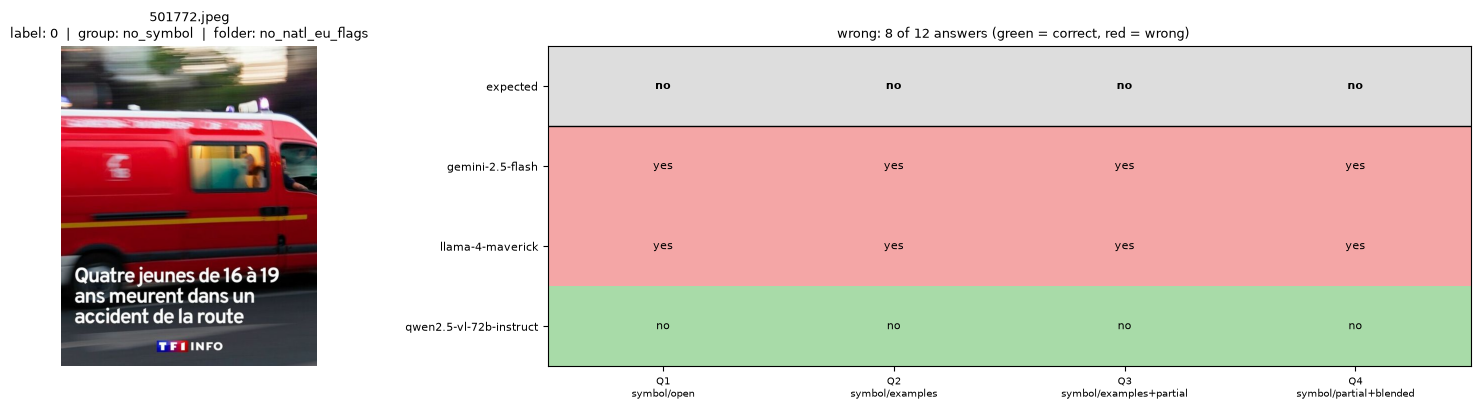

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,no,yes,"Yes, the picture depicts a national symbol. The logo ""18"" on the side of the red vehicle is the emergency number for firefighters in France, which is a national"
1,llama-4-maverick,Q1,no,yes,"The image shows a logo that includes the French flag, which is a national symbol."
2,gemini-2.5-flash,Q2,no,yes,"Yes, the picture depicts a national symbol. The logo ""18"" on the side of the red vehicle is the emergency telephone number for the fire brigade in France, which"
3,llama-4-maverick,Q2,no,yes,"Yes, the image depicts a national symbol, specifically the French flag, which is represented by the colors blue, white, and red in the logo ""TF1 INFO"" at the bo"
4,gemini-2.5-flash,Q3,no,yes,"Yes, the picture depicts a national symbol. The logo on the side of the red vehicle, which appears to be a fire truck or emergency vehicle, includes the number"
5,llama-4-maverick,Q3,no,yes,Yes.
6,gemini-2.5-flash,Q4,no,yes,"Yes, the picture depicts a national symbol. The logo ""18"" with a stylized flame, visible on the side of the red vehicle, is the emergency number for firefighter"
7,llama-4-maverick,Q4,no,yes,"Yes, the image depicts a French flag in the logo at the bottom."


> **Result:** `526263.jpeg` (eu_flag): 4 of 12 answers wrong by llama-4-maverick and qwen2.5-vl-72b-instruct; most often "unparsed" instead of "yes" (2x).<br>`510949.jpeg` (eu_flag): 3 of 12 answers wrong by qwen2.5-vl-72b-instruct; most often "unparsed" instead of "yes" (3x).<br>`503133.jpeg` (other_national_or_eu_symbol): 10 of 12 answers wrong by gemini-2.5-flash, qwen2.5-vl-72b-instruct and llama-4-maverick; most often "no" instead of "yes" (9x).<br>`592248.jpeg` (other_national_or_eu_symbol): 9 of 12 answers wrong by llama-4-maverick, qwen2.5-vl-72b-instruct and gemini-2.5-flash; most often "no" instead of "yes" (9x).<br>`501771.jpeg` (no_symbol): 8 of 12 answers wrong by llama-4-maverick, gemini-2.5-flash and qwen2.5-vl-72b-instruct; most often "yes" instead of "no" (8x).<br>`501772.jpeg` (no_symbol): 8 of 12 answers wrong by gemini-2.5-flash and llama-4-maverick; most often "yes" instead of "no" (8x).<br>Look at the images: errors on every question point to a hard image or a questionable label, errors on some questions to the wording.

In [17]:
U.show_difficult_images(run)